# 03 · Finding and fixing the weak spot: the repetition-penalty fingerprint
**Report sections:** Error analysis (Q4.3-Q4.4), Open-ended improvement (Q5)

Notebook `02` scored 0.941 on the Kaggle public leaderboard when blended with the SVM, but the language-model
classifier alone fell from 0.979 on validation to 0.914 on Kaggle. This notebook asks **which AI texts it misses**,
forms a hypothesis about why, and tests a targeted fix.

**Findings (numbers are in the tables below).**
- **The weak spot is "bumpy" AI text**: AI text whose token probabilities vary as much as a typical human text's
  (17% of AI texts). The notebook-02 classifier scores 0.986 on the other AI texts but 0.948 on these.
  Bumpy texts are also more common in `test.csv` (41%) than a train-like mix would give (33%).
- **These texts repeat themselves far less than natural writing**, the trace a repetition penalty would leave.
  GPT-2 expects much more repetition than it finds (`rp_deficit` alone: 0.87 on bumpy AI vs humans), half of them
  barely use the word "the", and almost every word appears once.
- **Adding repetition features fixes most of it.** Classifier alone: validation 0.979 -> 0.991, unseen domain
  0.976 -> 0.988, bumpy AI 0.941 -> 0.973. It is now ahead of the SVM on every number.
- **The blend improves a little**: unseen domain + layout removed 0.987 -> 0.991, bumpy AI 0.970 -> 0.979.
- **Not yet known:** the Kaggle score of the new files.

In [1]:
# --- setup: make `src/` and this folder importable from anywhere ---
import sys, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks" / "joling"))
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import SEED, set_seed, RESULTS_DIR
from src.data import get_split, load_test, load_train, load_unlabeled
from src.models import make_model
from src.features import has_blank_line_breaks
from src.evaluate import (auroc, predict_proba1, cross_val_auroc, log_result, savefig,
                          save_predictions, write_submission)

from domain_eval import TopicDomains, domain_stress_test, mean_auroc_by_domain
from lm_features import FEATURES, load_cached
from repetition_features import RP_FEATURES, WORD_FEATURES, load_cached as load_repetition
from lm_model import lm_boost, blend, blend_by_domain
from plots import plot_stress_summary, plot_feature_by_group, plot_weight_curve

set_seed(SEED)
pd.set_option("display.width", 220)

## Data
The shared split, the cached features, and the per-text scores that notebook `02` saved (so the SVM does not have to
be refitted for the stress test). The repetition features were made once with
`python notebooks/joling/repetition_features.py` (about 30 minutes) and are stored in
`results/joling_repetition_features_gpt2.csv`.

In [3]:
train_df, val_df = get_split()
test_df = load_test()
y_tr, y_va = train_df["label"].to_numpy(), val_df["label"].to_numpy()

lm = load_cached()                 # 24 predictability features
rep = load_repetition()            # 11 GPT-2 repetition features + 19 word-count repetition features
print(f"repetition cache: {rep.shape[0]:,} texts, missing values: {int(rep[RP_FEATURES + WORD_FEATURES].isna().sum().sum())}")

val_scores = pd.read_csv(RESULTS_DIR / "joling_scores_val.csv")
train_unseen = pd.read_csv(RESULTS_DIR / "joling_scores_train_unseen.csv")
S = val_scores[val_scores.model == "svm"].set_index("id").loc[val_df["id"]]           # SVM, validation rows
L0 = val_scores[val_scores.model == "lm_boost"].set_index("id").loc[val_df["id"]]     # notebook 02's classifier
S_tr = train_unseen[train_unseen.model == "svm"].set_index("id").loc[train_df["id"]]  # SVM, unseen-domain scores of training rows

domains = TopicDomains(k=8).fit(train_df["text"])
dom_tr, dom_va = domains.predict(train_df["text"]), domains.predict(val_df["text"])
assert (dom_va == S["domain"].to_numpy()).all() and (dom_tr == S_tr["domain"].to_numpy()).all()   # same domains as notebook 02

[train] raw=10000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=10000 (clean=True)
split: train=8000 (AI=0.500)  val=2000 (AI=0.500)  quick=False clean=True


[test] raw=3000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=3000 (clean=True)
repetition cache: 16,000 texts, missing values: 0


## Step 1 · Which AI texts does the notebook-02 classifier miss?
Its strongest single feature was `ll_std`, the spread of token log-probabilities: human text is "bumpy" (some tokens
easy to guess, some very hard), most AI text is "smooth". So we split the AI texts by that feature:

- **smooth AI**: `ll_std` below the median of human training texts (what the classifier expects AI to look like)
- **bumpy AI**: `ll_std` at or above that median (AI text that is as bumpy as a typical human text)

and score each group against **all** human validation texts. The threshold comes from training rows only.

In [4]:
full = load_train(verbose=False)
human_median = lm.loc[full["id"][full["label"] == 0], "ll_std"].median()
bumpy_val = lm.loc[val_df["id"], "ll_std"].to_numpy() >= human_median
is_ai = y_va == 1
GROUPS = {"smooth AI vs humans": (is_ai & ~bumpy_val) | ~is_ai, "bumpy AI vs humans": (is_ai & bumpy_val) | ~is_ai}


def by_group(p):
    p = np.asarray(p)
    return {g: auroc(y_va[m], p[m]) for g, m in GROUPS.items()}


weak = pd.DataFrame({
    "AI texts in group": {"smooth AI vs humans": int((is_ai & ~bumpy_val).sum()), "bumpy AI vs humans": int((is_ai & bumpy_val).sum())},
    "notebook-02 classifier": by_group(L0["p_standard"]), "SVM": by_group(S["p_standard"]),
    "notebook-02 classifier, unseen domain": by_group(L0["p_unseen"]), "SVM, unseen domain": by_group(S["p_unseen_layout_removed"]),
})
weak.to_csv(RESULTS_DIR / "joling_weak_spot.csv")
display(weak.round(4))

# How common are bumpy texts (human or AI) in each file? Labels are not needed for this.
share = {name: float((lm.loc[ids, "ll_std"] >= human_median).mean()) for name, ids in
         {"train humans": full["id"][full.label == 0], "train AI": full["id"][full.label == 1],
          "unlabeled": load_unlabeled(verbose=False)["id"], "test": test_df["id"]}.items()}
print("share of texts at or above the human median of ll_std:", {k: round(v, 3) for k, v in share.items()})
print("expected for a 50/50 mix that looks like train:", round((share["train humans"] + share["train AI"]) / 2, 3))

,AI texts in group,notebook-02 classifier,SVM,"notebook-02 classifier, unseen domain","SVM, unseen domain"
smooth AI vs humans,832,0.9858,0.9788,0.9818,0.9245
bumpy AI vs humans,168,0.9478,0.9772,0.9408,0.9462


share of texts at or above the human median of ll_std: {'train humans': 0.5, 'train AI': 0.166, 'unlabeled': 0.33, 'test': 0.415}
expected for a 50/50 mix that looks like train: 0.333


**Reading the table.** The predictability classifier is very good on smooth AI and clearly weaker on bumpy AI, where
the SVM is the better model. And bumpy texts are more common in `test.csv` than a train-like mix would give, so this
weak spot matters more on Kaggle than on validation.

## Step 2 · Hypothesis: these texts were generated with a repetition penalty
The RAID benchmark paper (Dugan et al., ACL 2024) reports that detectors lose up to 32 points of accuracy on text
generated with a **repetition penalty**, a setting that pushes a generator away from tokens it has already used. Such
text is less predictable, which would explain "bumpy AI". If that is what we are looking at, it should leave a
different trace: the text should **repeat itself less than natural writing does**.

Two ways to measure that (see `repetition_features.py`):
- **word counts** (19 features, no model): e.g. the share of words used only once, repeats within the last 10 words;
- **GPT-2 repetition features** (11 features): at each position GPT-2 gives a probability that the next token is one
  already used. Averaged, that is the repetition we *expect*; we compare it with the repetition that *happened*.

We only use the paper's finding as an idea for features. No outside data or labels are used.

In [5]:
R_va = rep.loc[val_df["id"]]
single = pd.DataFrame({"all AI vs humans": {f: auroc(y_va, R_va[f]) for f in RP_FEATURES + WORD_FEATURES}})
for g, m in GROUPS.items():
    single[g] = [auroc(y_va[m], R_va[f].to_numpy()[m]) for f in single.index]
single["kind"] = ["GPT-2" if f in RP_FEATURES else "word count" for f in single.index]
single["strength on bumpy AI"] = (single["bumpy AI vs humans"] - 0.5).abs() + 0.5
single = single.sort_values("strength on bumpy AI", ascending=False)
single.to_csv(RESULTS_DIR / "joling_repetition_single_feature.csv")
single.head(12).round(3)

,all AI vs humans,smooth AI vs humans,bumpy AI vs humans,kind,strength on bumpy AI
rp_ratio,0.297,0.332,0.125,GPT-2,0.875
rp_deficit_late,0.703,0.668,0.875,GPT-2,0.875
rp_deficit,0.663,0.621,0.868,GPT-2,0.868
rp_z,0.643,0.598,0.866,GPT-2,0.866
ttr,0.578,0.521,0.863,word count,0.863
hapax_share,0.612,0.561,0.862,word count,0.862
rp_actual,0.441,0.501,0.145,GPT-2,0.855
repeat_w50,0.425,0.481,0.150,word count,0.850
stop_ttr,0.589,0.538,0.847,word count,0.847
repeat_w10,0.401,0.450,0.158,word count,0.842


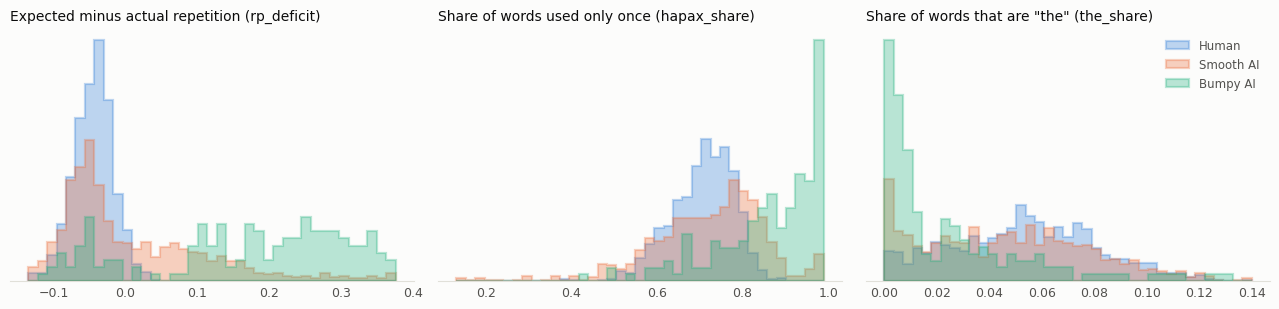

In [6]:
group_name = np.where(~is_ai, "Human", np.where(bumpy_val, "Bumpy AI", "Smooth AI"))
fig = plot_feature_by_group(R_va, group_name, ["rp_deficit", "hapax_share", "the_share"],
                            ["Expected minus actual repetition (rp_deficit)", "Share of words used only once (hapax_share)",
                             'Share of words that are "the" (the_share)'], order=["Human", "Smooth AI", "Bumpy AI"])
savefig(fig, "joling_repetition_groups");

## Step 3 · Does adding these features fix the weak spot?
Four feature sets, same boosted-tree settings as notebook `02` (held fixed, so only the features change).
For each: 5-fold cross-validation on the training rows, then the stress test on the validation set, plus the two
subgroups from Step 1 under the unseen-domain condition.

In [7]:
cv02 = pd.read_csv(RESULTS_DIR / "joling_lm_cv.csv")
best = cv02[cv02.setting.str.startswith("boost")].sort_values("cv_auroc_mean").iloc[-1]["setting"]   # e.g. "boost depth=3 lr=0.1"
DEPTH, LR = int(best.split("depth=")[1].split()[0]), float(best.split("lr=")[1])
print("booster settings from notebook 02:", best)

SETS = {"predictability (24) = notebook 02": FEATURES,
        "+ word-count repetition (19)": FEATURES + WORD_FEATURES,
        "+ GPT-2 repetition (11)": FEATURES + RP_FEATURES,
        "+ both (30)": FEATURES + RP_FEATURES + WORD_FEATURES}
make = {name: (lambda cols=cols: lm_boost(max_depth=DEPTH, learning_rate=LR, columns=cols)) for name, cols in SETS.items()}

rows, new_val, new_train_unseen = [], {}, {}
for name in SETS:
    t0 = time.time()
    cv = cross_val_auroc(make[name](), train_df["text"], y_tr)
    summ, _, preds = domain_stress_test(make[name], train_df, val_df, dom_tr, dom_va, verbose=False, score_train=True)
    new_train_unseen[name] = preds.attrs.pop("train_unseen")
    new_val[name] = preds
    train_auc = auroc(y_tr, predict_proba1(make[name]().fit(train_df["text"], y_tr), train_df["text"]))
    g = by_group(preds["p_unseen"])
    rows.append({"features": name, "n_features": len(SETS[name]), "cv_auroc (train rows)": cv["cv_auroc_mean"],
                 "train_auroc": train_auc, "val_auroc": summ["val_auroc"], "unseen_domain_mean": summ["unseen_domain_mean"],
                 "smooth AI (unseen)": g["smooth AI vs humans"], "bumpy AI (unseen)": g["bumpy AI vs humans"],
                 "seconds": round(time.time() - t0)})
ablation = pd.DataFrame(rows)
ablation.to_csv(RESULTS_DIR / "joling_repetition_ablation.csv", index=False)

# The feature set for the rest of the notebook: best cross-validation score on the training rows.
CHOSEN = ablation.sort_values("cv_auroc (train rows)").iloc[-1]["features"]
print("chosen feature set:", CHOSEN)
ablation.round(4)

booster settings from notebook 02: boost depth=3 lr=0.1


chosen feature set: + both (30)


,features,n_features,cv_auroc (train rows),train_auroc,val_auroc,unseen_domain_mean,smooth AI (unseen),bumpy AI (unseen),seconds
0,predictability (24) = notebook 02,24,0.9720,0.9942,0.9794,0.9761,0.9818,0.9408,18
1,+ word-count repetition (19),43,0.9862,0.9991,0.9884,0.9847,0.9899,0.9540,16
2,+ GPT-2 repetition (11),35,0.9886,0.9996,0.9891,0.9864,0.9912,0.9688,18
3,+ both (30),54,0.9888,0.9998,0.9908,0.9880,0.9926,0.9725,18


## Step 4 · Blend with the SVM again
Same recipe as notebook `02`: rank average with the SVM, weight chosen on training rows scored by models that did
not see their domain. The notebook-02 blend (weight 0.6) is shown for comparison.

chosen weight of the new classifier: 0.8


,model,val_auroc,val_layout_removed,unseen_domain_mean,unseen_layout_removed_mean,"bumpy AI (unseen, layout removed)","smooth AI (unseen, layout removed)"
0,svm (robust_svm_tuned),0.9786,0.9786,0.9328,0.9328,0.9462,0.9245
1,notebook 02: classifier,0.9794,0.9794,0.9761,0.9761,0.9408,0.9818
2,notebook 02: svm + blank + classifier (w=0.6),0.9949,0.9934,0.9914,0.9866,0.9704,0.9883
3,new classifier,0.9908,0.9908,0.9880,0.9880,0.9725,0.9926
4,new: svm + classifier (w=0.8),0.9948,0.9948,0.9909,0.9909,0.9787,0.9926
5,new: svm + blank + classifier (w=0.8),0.9956,0.9948,0.9931,0.9909,0.9787,0.9926


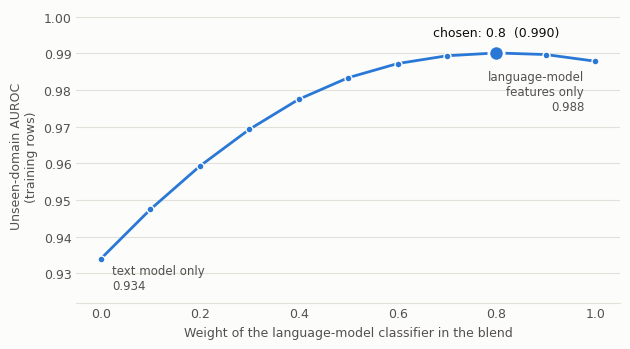

In [8]:
def blank_push(p, texts, push=0.1):
    b = np.array([has_blank_line_breaks(t) for t in texts], dtype=float)
    return (np.asarray(p) + push * b) / (1 + push)


def numbers(std, flat, unseen, unseen_flat):
    return {"val_auroc": auroc(y_va, std), "val_layout_removed": auroc(y_va, flat),
            "unseen_domain_mean": mean_auroc_by_domain(y_va, unseen, dom_va),
            "unseen_layout_removed_mean": mean_auroc_by_domain(y_va, unseen_flat, dom_va),
            "bumpy AI (unseen, layout removed)": by_group(unseen_flat)["bumpy AI vs humans"],
            "smooth AI (unseen, layout removed)": by_group(unseen_flat)["smooth AI vs humans"]}


L1, L1_tr = new_val[CHOSEN], new_train_unseen[CHOSEN]
weights = np.round(np.arange(0, 1.01, 0.1), 1)
curve = [mean_auroc_by_domain(y_tr, blend_by_domain(S_tr["p_unseen_layout_removed"], L1_tr["p_unseen"], dom_tr, w), dom_tr)
         for w in weights]
W = float(weights[int(np.argmax(curve))])
pd.DataFrame({"lm_weight": weights, "train_unseen_auroc": curve}).to_csv(RESULTS_DIR / "joling_blend_weights_03.csv", index=False)
print("chosen weight of the new classifier:", W)
fig = plot_weight_curve(weights, curve, W)
savefig(fig, "joling_blend_weight_03");

sb = {"std": blank_push(S["p_standard"], val_df["text"]), "flat": S["p_layout_removed"].to_numpy(),
      "unseen": blank_push(S["p_unseen"], val_df["text"]), "unseen_flat": S["p_unseen_layout_removed"].to_numpy()}


def blended(text, lmv, w):
    return numbers(blend(text["std"], lmv["p_standard"], w), blend(text["flat"], lmv["p_layout_removed"], w),
                   blend_by_domain(text["unseen"], lmv["p_unseen"], dom_va, w),
                   blend_by_domain(text["unseen_flat"], lmv["p_unseen_layout_removed"], dom_va, w))


sv = {"std": S["p_standard"], "flat": S["p_layout_removed"], "unseen": S["p_unseen"], "unseen_flat": S["p_unseen_layout_removed"]}
table = pd.DataFrame({
    "svm (robust_svm_tuned)": numbers(sv["std"], sv["flat"], sv["unseen"], sv["unseen_flat"]),
    "notebook 02: classifier": numbers(L0["p_standard"], L0["p_layout_removed"], L0["p_unseen"], L0["p_unseen_layout_removed"]),
    "notebook 02: svm + blank + classifier (w=0.6)": blended(sb, L0, 0.6),
    "new classifier": numbers(L1["p_standard"], L1["p_layout_removed"], L1["p_unseen"], L1["p_unseen_layout_removed"]),
    f"new: svm + classifier (w={W})": blended(sv, L1, W),
    f"new: svm + blank + classifier (w={W})": blended(sb, L1, W),
}).T.rename_axis("model").reset_index()
table.to_csv(RESULTS_DIR / "joling_repetition_blend.csv", index=False)
for _, r in table.iterrows():
    log_result("joling_repetition_blend_log", {"model": r["model"], "features": CHOSEN, "lm_weight": W, "seed": SEED},
               {c: r[c] for c in table.columns[1:]})
table.round(4)

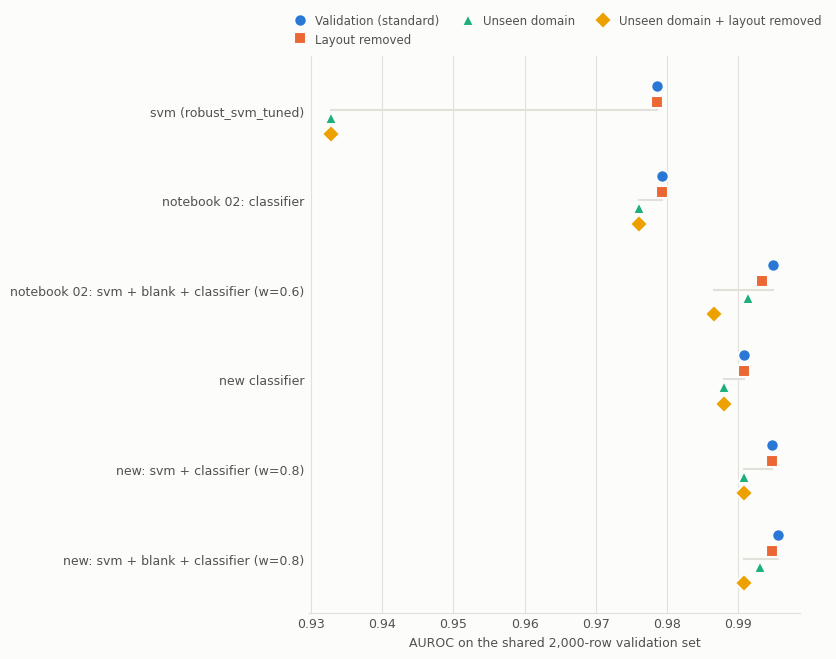

In [9]:
fig = plot_stress_summary(table)
savefig(fig, "joling_repetition_blend_summary");

## Step 5 · Train on all 10,000 labelled rows and write the Kaggle files

In [10]:
full_df = pd.concat([train_df, val_df], ignore_index=True)
lm_all = make[CHOSEN]().fit(full_df["text"], full_df["label"])
svm_all = make_model("robust_svm_tuned").fit(full_df["text"], full_df["label"])

t_lm = predict_proba1(lm_all, test_df["text"])
t_svm = predict_proba1(svm_all, test_df["text"])
t_blend, t_blend_blank = blend(t_svm, t_lm, W), blend(blank_push(t_svm, test_df["text"]), t_lm, W)

old = pd.read_csv(RESULTS_DIR / "preds_joling_lm.csv").query("split == 'test'").set_index("id").loc[test_df["id"], "prob"].to_numpy()
print("share of test texts scored above 0.5:  notebook-02 classifier", round(float((old >= 0.5).mean()), 3),
      "| new classifier", round(float((t_lm >= 0.5).mean()), 3), "| SVM", round(float((t_svm >= 0.5).mean()), 3))
bumpy_test = lm.loc[test_df["id"], "ll_std"].to_numpy() >= human_median
print("... among bumpy test texts:              notebook-02 classifier", round(float((old[bumpy_test] >= 0.5).mean()), 3),
      "| new classifier", round(float((t_lm[bumpy_test] >= 0.5).mean()), 3), "| SVM", round(float((t_svm[bumpy_test] >= 0.5).mean()), 3))

save_predictions("joling_lm_rp", val_df, L1["p_standard"], test_df, t_lm)
save_predictions("joling_blend_rp", val_df, blend(S["p_standard"], L1["p_standard"], W), test_df, t_blend)
save_predictions("joling_blend_rp_blank", val_df, blend(sb["std"], L1["p_standard"], W), test_df, t_blend_blank)

write_submission(test_df, t_lm, tag="joling_lm_rp")
write_submission(test_df, t_blend, tag="joling_blend_rp")
write_submission(test_df, t_blend_blank, tag="joling_blend_rp_blank");

share of test texts scored above 0.5:  notebook-02 classifier 0.4 | new classifier 0.398 | SVM 0.366
... among bumpy test texts:              notebook-02 classifier 0.124 | new classifier 0.124 | SVM 0.144
saved results/preds_joling_lm_rp.csv
saved results/preds_joling_blend_rp.csv
saved results/preds_joling_blend_rp_blank.csv
wrote submissions/submission_20261110_213132_joling_lm_rp.csv (3000 rows) - validated OK
wrote submissions/submission_20261110_213132_joling_blend_rp.csv (3000 rows) - validated OK
wrote submissions/submission_20261110_213132_joling_blend_rp_blank.csv (3000 rows) - validated OK


## What we learned
1. Splitting errors by an observable property of the text (here: how bumpy it is) showed that one classifier's
   weakness was concentrated in a small group, and that the SVM did not share it.
2. The group has a clear cause we could test. Text generated under a repetition penalty looks unpredictable, which
   fooled the predictability features, but it avoids words it has already used. Comparing the repetition GPT-2
   *expects* with the repetition that *happens* separates these texts from human writing far better than word
   counts alone (bumpy AI: 0.969 with the GPT-2 features, 0.954 with word counts, 0.973 with both).
3. Because the classifier now covers its own weak spot, the weight chosen for it in the blend rises from 0.6 to 0.8,
   and the SVM contributes less than before.

## Limits
- We never see how any text was generated, so "repetition penalty" is a hypothesis that fits the evidence, not a fact.
- The boosted model now fits the training rows almost perfectly (training AUROC 0.9998, validation 0.991).
- On the bumpy *test* texts the new classifier flags the same share as AI as the old one did (12%). Either most bumpy
  test texts are human (for example poems), or the test set has bumpy AI text of a kind these features do not catch.
  Only the Kaggle score can tell.
- The gain for the blend on our stress test is small (0.004), close to what the public leaderboard can resolve.

## Next
Upload the three new files and compare with 0.936 / 0.941 from notebook `02`.